# STACKING MODEL: RANDOM FOREST,  XGBOOST, MLPRegressor + LINEAR REGRESSION KAO META-MODEL

### Priprema modela

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Učitaj podatke
df = pd.read_csv("output/spojeni_podaci.csv")

# Dodaj vremenske značajke ako nisu već u CSV-u
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["dan_u_tjednu"] = df["Date"].dt.dayofweek
df["mjesec"] = df["Date"].dt.month
df["dan_u_godini"] = df["Date"].dt.dayofyear
#df["temp_naoblaka_ratio"] = df["temperatura"] / (df["naoblaka"] + 1e-5)

# Značajke i ciljna varijabla
features = [
    "insolacija", "naoblaka", "temperatura", "Peak Power (kW)",
    "dan_u_tjednu", "mjesec", "dan_u_godini"
]
target = "PV Yield (kWh)"

df = df[features + [target]].dropna()

# Odvajanje ulaza i cilja
X = df[features]
y = df[target]

# Skaliranje
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Podjela na train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

### Inicijalizacija modela i treniranje

In [3]:

# Bazni modeli
rf = RandomForestRegressor(n_estimators=100, random_state=42)
xgb = XGBRegressor(objective="reg:squarederror", n_estimators=100, random_state=42)
mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42, early_stopping=True)

# Treniranje baznih modela
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)
mlp.fit(X_train, y_train)

# Predikcije baznih modela (na test skupu)
rf_pred = rf.predict(X_test)
xgb_pred = xgb.predict(X_test)
mlp_pred = mlp.predict(X_test)

# Ulazi za meta-model: kombinacija predikcija
meta_features = np.column_stack((rf_pred, xgb_pred))

# Meta-model (stacker)
meta_model = LinearRegression()
meta_model.fit(meta_features, y_test)

# Konačne predikcije
final_pred = meta_model.predict(meta_features)

### Evaluacija rezultata

In [4]:
# Evaluacija
mae = mean_absolute_error(y_test, final_pred)
mse = mean_squared_error(y_test, final_pred)
r2 = r2_score(y_test, final_pred)

print("Evaluacija stacking modela:")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R²: {r2:.2f}")

Evaluacija stacking modela:
MAE: 1.75
MSE: 7.06
R²: 0.93


### Vizaulizacija

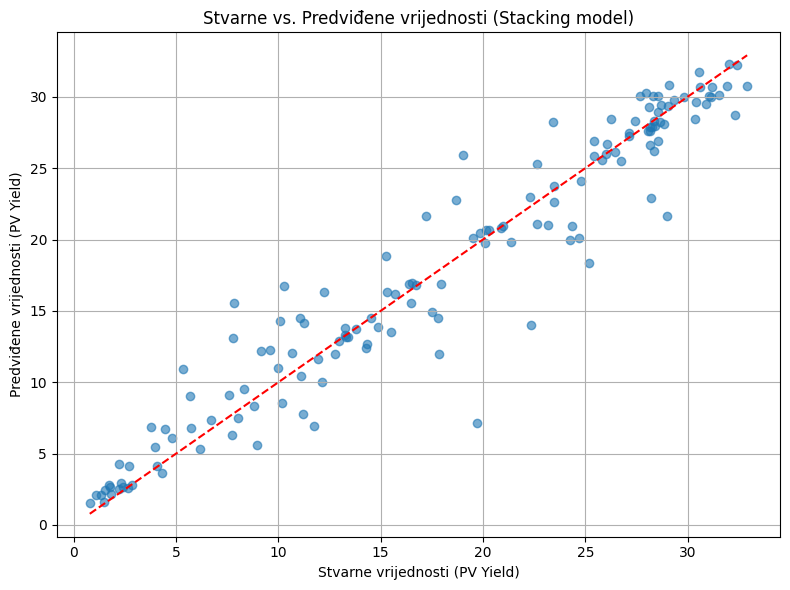

In [6]:
import matplotlib.pyplot as plt

# Scatter graf: stvarne vs. predviđene vrijednosti
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Idealna linija
plt.xlabel("Stvarne vrijednosti (PV Yield)")
plt.ylabel("Predviđene vrijednosti (PV Yield)")
plt.title("Stvarne vs. Predviđene vrijednosti (Stacking model)")
plt.grid(True)
plt.tight_layout()
plt.savefig("grafovi/RFXGLR.png")
plt.show()